# Assignment 08: Species Distribution Modeling with elapid

## BIO597 Spatial Analysis of Biodiversity

Use `elapid` to prepare spatial data, fit a MaxEnt model, and ask how evaluation changes when we withhold whole geographic areas. You may reuse code from Lab08.

## Deliverable

Submit this completed notebook with maps, climate comparisons, ROC curves, an AUC summary table, and short written answers. Save your modeling points and AUC table. Use the lab's model defaults; no parameter search or suitability-raster export is required.


## 1. Import packages and load the occurrence records

Run this notebook from `docs/assignments`. The imports are provided so you can focus on the SDM workflow. If elapid is unavailable, use the same environment or installation instructions as the lab.

`np.random.seed(597)` makes the background draws repeatable when the notebook runs from top to bottom.


In [2]:
pip install elapid

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [elapid]
Note: you may need to restart the kernel to use updated packages.


In [27]:
from pprint import pprint

In [3]:
import elapid as ela
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from rasterio import plot as rioplot
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.metrics import RocCurveDisplay

np.random.seed(597)
amphibians = gpd.read_file("../data/amphibians.geojson")
amphibians["species"].value_counts().head(12)


species
Pseudacris crucifer          1839
Aquarana clamitans           1779
Anaxyrus americanus          1689
Boreorana sylvatica          1617
Lithobates catesbeianus      1487
Ambystoma maculatum          1317
Plethodon cinereus           1283
Lithobates palustris         1049
Dryophytes versicolor         790
Notophthalmus viridescens     611
Lithobates pipiens            326
Hemidactylium scutatum        233
Name: count, dtype: int64

## 2. Choose a species

Choose a common Maine amphibian other than the lab's pickerel frog (*Lithobates palustris*). Start with at least 200 records. Filter the occurrence table to your species and store the result as `species_points`.


In [5]:
target_species = "Dryophytes versicolor"
presence = amphibians[amphibians["species"] == target_species].copy()
presence = presence[presence["coordinateUncertaintyInMeters"] < 100].copy()

print("Number of records:", len(presence))
print("CRS: ", presence.crs)

# Select your species and store a copy as species_points.
# Print the record count and coordinate reference system.


Number of records: 725
CRS:  EPSG:4326


**Why this species?** Give one biological reason for your choice. This is the tree frog so it would be cool to see how closely it follows forest habitats.

## 3. Set up the climate rasters

Use the same 19 Maine bioclimatic rasters as the lab. The filenames and readable column names are provided below. Their order matters: each label must describe the corresponding raster.


In [6]:
bioclim_names = {
    'wc2.1_2.5m_bio_1.tif':  'Annual mean temperature',
    'wc2.1_2.5m_bio_2.tif':  'Mean diurnal temperature range',
    'wc2.1_2.5m_bio_3.tif':  'Isothermality',
    'wc2.1_2.5m_bio_4.tif':  'Temperature seasonality',
    'wc2.1_2.5m_bio_5.tif':  'Max temperature, warmest month',
    'wc2.1_2.5m_bio_6.tif':  'Min temperature, coldest month',
    'wc2.1_2.5m_bio_7.tif':  'Annual temperature range',
    'wc2.1_2.5m_bio_8.tif':  'Mean temperature, wettest quarter',
    'wc2.1_2.5m_bio_9.tif':  'Mean temperature, driest quarter',
    'wc2.1_2.5m_bio_10.tif': 'Mean temperature, warmest quarter',
    'wc2.1_2.5m_bio_11.tif': 'Mean temperature, coldest quarter',
    'wc2.1_2.5m_bio_12.tif': 'Annual precipitation',
    'wc2.1_2.5m_bio_13.tif': 'Precipitation, wettest month',
    'wc2.1_2.5m_bio_14.tif': 'Precipitation, driest month',
    'wc2.1_2.5m_bio_15.tif': 'Precipitation seasonality',
    'wc2.1_2.5m_bio_16.tif': 'Precipitation, wettest quarter',
    'wc2.1_2.5m_bio_17.tif': 'Precipitation, driest quarter',
    'wc2.1_2.5m_bio_18.tif': 'Precipitation, warmest quarter',
    'wc2.1_2.5m_bio_19.tif': 'Precipitation, coldest quarter',
}

rasters = [f"../data/bioclim_ME/{var}" for var in bioclim_names]
labels = list(bioclim_names.values())


## 4. Map the records over temperature

Open `rasters[0]` (annual mean temperature), plot it with `rioplot.show()`, and overlay your species' points. Reproject the points to the raster CRS when plotting, as in the lab. Keep this first raster path as `mean_temp_raster` for sampling.


/srv/conda/envs/notebook/lib/python3.13/site-packages/matplotlib/colors.py:816: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


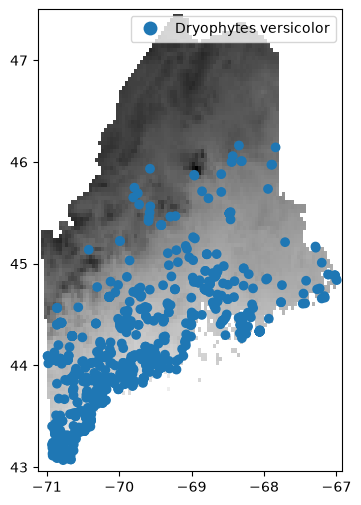

In [7]:
mean_temp_raster = rasters[0]

# Plot annual mean temperature and overlay species_points.
# Add a title naming your species.
# first we'll just read and display the surface temperature data
fig, ax = plt.subplots(figsize=(6,6))

with rio.open(mean_temp_raster, 'r') as src:
    
    # this plots the mean annual temperature data
    # low temps are dark grey, high temps are light grey
    rioplot.show(src, ax=ax, cmap="gray")
    
    # overlay the ariolimax data
    presence.to_crs(src.crs).plot(column='species', ax=ax, legend=True)

**Interpretation:** Are records spread across Maine or concentrated in particular places? Why might a gap in records fail to indicate a true absence? records are definitely centered around populed areas in maine rather than areas further north.

## 5. Compare two background samples

Draw 1,000 points with `ela.sample_raster()` and another 1,000 with `ela.sample_bias_file()`, using annual mean temperature as the bias file. Drop duplicate geometries in each sample, following the lab, and report the remaining counts. Map the two samples side by side.

The biased sample favors cells with larger temperature values. This is a demonstration of sampling bias; temperature alone does not establish where observers actually searched.


count                                     917
unique                                    917
top       POINT (-67.1875 45.104166666666664)
freq                                        1
dtype: object

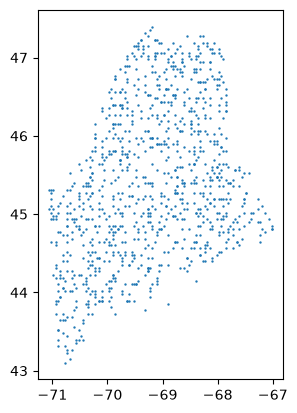

In [10]:
count = 1000

# Create pseudoabsence with ela.sample_raster().
# Create pseudoabsence_bias with ela.sample_bias_file().
# Drop duplicate points, print the remaining counts, and map both samples.
pseudoabsence = ela.sample_raster(mean_temp_raster, count)

# plotting
pseudoabsence.plot(markersize=0.5)
pseudoabsence.describe()

# you can drop them if you'd like.
pseudoabsence.drop_duplicates(inplace=True)
pseudoabsence.describe()

count                                   1000
unique                                   908
top       POINT (-68.14583333333333 44.6875)
freq                                       4
dtype: object

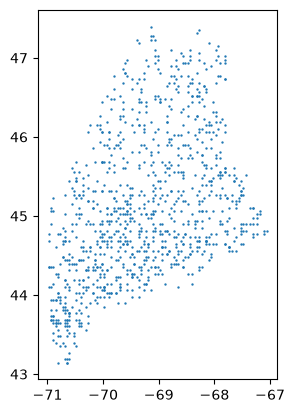

In [11]:
mean_temp_raster = rasters[0]
pseudoabsence_bias = ela.sample_bias_file(mean_temp_raster, count)
pseudoabsence_bias.plot(markersize=0.5)
pseudoabsence_bias.describe()

**Interpretation:** How do the two geographic samples differ? Explain why background choice can change the species–climate relationship learned by a model. The background incorporates climate points that covers the entire geographical clip. This influences the range of places with the appropiate suitability. The bias background may be better because it takes into consideration where sampling can be biased to different temperature ranges.

Choose one sample for the remaining analysis and keep it fixed. The line below uses the uniform sample; change it to `pseudoabsence_bias` if you choose the biased sample.

**Background choice and justification:** I am choosing the bias because it is more robust to randomness


In [12]:
background_points = pseudoabsence_bias


## 6. Extract climate values with `ela.annotate()`

Annotate `species_points.geometry` and your chosen `background_points` using `rasters`, `labels`, `drop_na=True`, and `quiet=True`. Store the results as `presence` and `background`. Report the number of usable rows in each table.

Annotation means extracting raster values at point locations. `drop_na=True` removes points falling on raster NoData cells.


In [14]:
# Annotate presence and background points, following Lab08.
# Print the usable counts and display presence.head().
presence = ela.annotate(
    presence.geometry,
    rasters,
    labels=labels,
    drop_na=True,
    quiet=True,
)

# we'll use the biased sample locations
background = ela.annotate(
    pseudoabsence_bias,
    rasters,
    labels=labels,
    drop_na=True,
    quiet=True,
)

In [18]:
print(presence.count())
display(presence.head())

Annual mean temperature              657
Mean diurnal temperature range       657
Isothermality                        657
Temperature seasonality              657
Max temperature, warmest month       657
Min temperature, coldest month       657
Annual temperature range             657
Mean temperature, wettest quarter    657
Mean temperature, driest quarter     657
Mean temperature, warmest quarter    657
Mean temperature, coldest quarter    657
Annual precipitation                 657
Precipitation, wettest month         657
Precipitation, driest month          657
Precipitation seasonality            657
Precipitation, wettest quarter       657
Precipitation, driest quarter        657
Precipitation, warmest quarter       657
Precipitation, coldest quarter       657
geometry                             657
dtype: int64


,Annual mean temperature,Mean diurnal temperature range,Isothermality,Temperature seasonality,"Max temperature, warmest month","Min temperature, coldest month",Annual temperature range,"Mean temperature, wettest quarter","Mean temperature, driest quarter","Mean temperature, warmest quarter","Mean temperature, coldest quarter",Annual precipitation,"Precipitation, wettest month","Precipitation, driest month",Precipitation seasonality,"Precipitation, wettest quarter","Precipitation, driest quarter","Precipitation, warmest quarter","Precipitation, coldest quarter",geometry
0,8.071000,11.260000,30.350405,922.830444,26.840000,-10.260,37.099998,3.802000,19.408667,19.408667,-3.490667,1144.0,124.0,82.0,13.125590,335.0,252.0,252.0,281.0,POINT (-70.58929 43.31999)
1,7.176833,10.757667,28.090836,977.089783,26.152000,-12.144,38.296001,2.706667,18.220667,19.052000,-5.226000,1143.0,114.0,81.0,11.788889,325.0,249.0,256.0,284.0,POINT (-70.10559 44.02318)
2,7.481333,10.960000,29.006987,953.498962,26.080000,-11.704,37.784000,3.174667,18.316000,19.039999,-4.619333,1162.0,120.0,82.0,12.964702,337.0,251.0,252.0,291.0,POINT (-70.29315 43.73292)
3,7.567667,10.810667,28.886988,948.200500,26.064001,-11.360,37.424000,3.270667,19.081333,19.081333,-4.444667,1154.0,119.0,81.0,13.038893,335.0,249.0,249.0,290.0,POINT (-70.27082 43.73662)
4,7.481333,10.960000,29.006987,953.498962,26.080000,-11.704,37.784000,3.174667,18.316000,19.039999,-4.619333,1162.0,120.0,82.0,12.964702,337.0,251.0,252.0,291.0,POINT (-70.29314 43.73294)


## 7. Compare recorded and available environments

Use the plotting recipe below to compare annual mean temperature, annual precipitation, and precipitation seasonality. These are the same three variables considered in Lab07. Density-scaled histograms let us compare shapes despite different sample sizes.


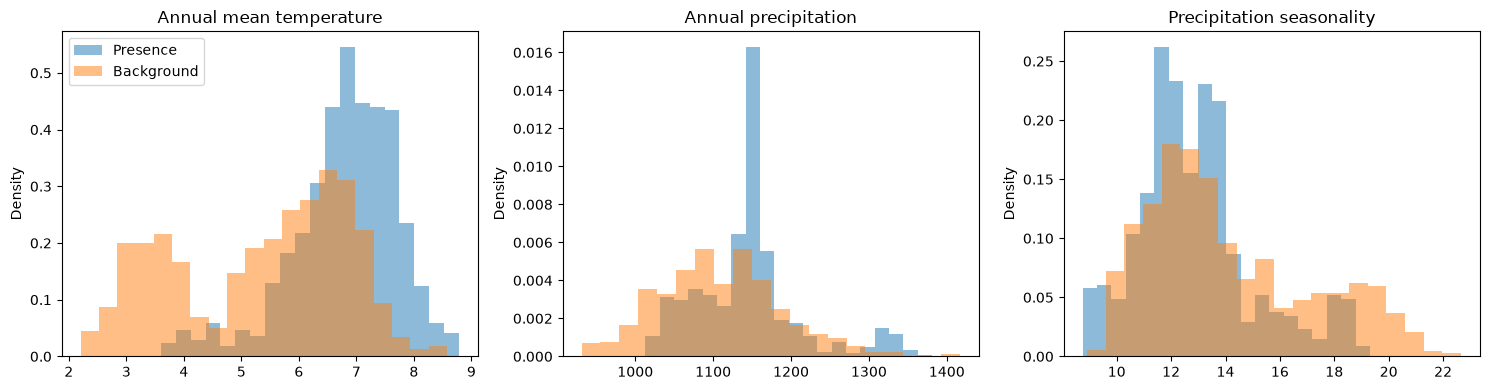

In [19]:
comparison_labels = [labels[0], labels[11], labels[14]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for label, ax in zip(comparison_labels, axes):
    ax.hist(presence[label], bins=20, density=True, alpha=0.5, label="Presence")
    ax.hist(background[label], bins=20, density=True, alpha=0.5, label="Background")
    ax.set_title(label)
    ax.set_ylabel("Density")

axes[0].legend()
plt.tight_layout()
plt.show()


**Interpretation:** Choose one variable. Does your species' recorded environment differ from the sampled background? Describe the pattern without assuming it proves a habitat preference. It does not differ greatly from the sampled background, except for MAT where the presence exceeds the background temperatures.

## 8. Calculate geographic sample weights

Following the lab, use `ela.distance_weights(..., n_neighbors=-1)` to calculate a `SampleWeight` column separately for presence and background. Pass points projected to `EPSG:26919`, which uses meters. Plot presence points colored by their weights.

The weights give relatively isolated observations more influence than observations in dense clusters. They do not turn an unobserved location into a confirmed absence.


<Axes: >

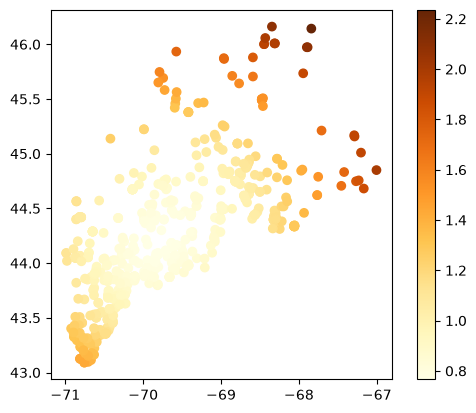

In [20]:
# Calculate presence["SampleWeight"] using presence.to_crs("EPSG:26919").
# Calculate background["SampleWeight"] the same way.
# Plot the presence weights with a legend.

background['SampleWeight'] = ela.distance_weights(background.to_crs('EPSG:26919'), n_neighbors=-1)
presence['SampleWeight'] = ela.distance_weights(presence.to_crs('EPSG:26919'), n_neighbors=-1)
presence.plot(column='SampleWeight', legend=True, cmap='YlOrBr')


**Interpretation:** Where are the largest weights? Why would decimal degrees be a poor unit for the distance calculations? The largest weights are near populated areas of maine. distance in the other CRS can create distortions that are given by the geometry rather than meter distance.

## 9. Stack the tables and define predictors

Use `ela.stack_geodataframes(presence, background, add_class_label=True)` and project the result to `EPSG:26919`. Call the result `merged` and display the counts in its `class` column.

`class` is 1 for presence and 0 for background. Select only the named climate columns as predictors. `SampleWeight`, class labels, geometry, and later split labels must stay out of the predictor table.


In [21]:
merged = ela.stack_geodataframes(
    presence,
    background,
    add_class_label=True,
).to_crs('EPSG:26919')
merged.head()

,Annual mean temperature,Mean diurnal temperature range,Isothermality,Temperature seasonality,"Max temperature, warmest month","Min temperature, coldest month",Annual temperature range,"Mean temperature, wettest quarter","Mean temperature, driest quarter","Mean temperature, warmest quarter",...,"Precipitation, wettest month","Precipitation, driest month",Precipitation seasonality,"Precipitation, wettest quarter","Precipitation, driest quarter","Precipitation, warmest quarter","Precipitation, coldest quarter",geometry,SampleWeight,class
0,8.071000,11.260000,30.350405,922.830444,26.840000,-10.260,37.099998,3.802000,19.408667,19.408667,...,124.0,82.0,13.125590,335.0,252.0,252.0,281.0,POINT (371132.929 4797576.289),1.211590,1
1,7.176833,10.757667,28.090836,977.089783,26.152000,-12.144,38.296001,2.706667,18.220667,19.052000,...,114.0,81.0,11.788889,325.0,249.0,256.0,284.0,POINT (411394.367 4875041.14),0.791926,1
2,7.481333,10.960000,29.006987,953.498962,26.080000,-11.704,37.784000,3.174667,18.316000,19.039999,...,120.0,82.0,12.964702,337.0,251.0,252.0,291.0,POINT (395858.137 4843022.773),0.899538,1
3,7.567667,10.810667,28.886988,948.200500,26.064001,-11.360,37.424000,3.270667,19.081333,19.081333,...,119.0,81.0,13.038893,335.0,249.0,249.0,290.0,POINT (397663.397 4843405.322),0.893972,1
4,7.481333,10.960000,29.006987,953.498962,26.080000,-11.704,37.784000,3.174667,18.316000,19.039999,...,120.0,82.0,12.964702,337.0,251.0,252.0,291.0,POINT (395859.455 4843024.641),0.899528,1


In [25]:
# Stack presence and background as merged, then project it to EPSG:26919.
# Display the counts of each class.

X = merged[labels]
y = merged["class"]
sample_weight = merged["SampleWeight"]

merged['class'].describe()

count    1657.000000
mean        0.396500
std         0.489318
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         1.000000
Name: class, dtype: float64

## 10. Fit MaxEnt and calculate a training AUC

Create `maxent = ela.MaxentModel()` and fit it with `X`, `y`, and `sample_weight=sample_weight`. Predict scores for `X`.

This first check uses the same rows for learning and evaluation, as in the lab's “naive” model. It is a **training score**, not a test of new locations.

**ROC AUC** measures how well scores rank presence above background. A value near 0.5 indicates little ranking ability; a higher value indicates better separation of these labels. The ROC curve shows the tradeoff as we change the cutoff for calling a score high: more recorded presences exceed the cutoff, but more background points may exceed it too. AUC does not establish true occupancy probability.


In [28]:
maxent = ela.MaxentModel()
maxent.set_params(n_cpus=4)
pprint(maxent.get_params())
# Fit maxent with X, y, and sample_weight.
# Predict X and store the scores as naive_prediction.
# Calculate naive_auc with metrics.roc_auc_score(y, naive_prediction).
# Also calculate naive_weighted_auc using sample_weight=sample_weight.
# Print both scores and plot a ROC curve with RocCurveDisplay.from_predictions().


{'beta_categorical': 1.0,
 'beta_hinge': 1.0,
 'beta_lqp': 1.0,
 'beta_multiplier': 1.5,
 'beta_threshold': 1.0,
 'clamp': True,
 'class_weights': 100,
 'convergence_tolerance': 2e-06,
 'feature_types': ['linear', 'hinge', 'product'],
 'max_iter': 1000,
 'n_cpus': 4,
 'n_hinge_features': 10,
 'n_lambdas': 100,
 'n_threshold_features': 10,
 'random_state': None,
 'scorer': 'roc_auc',
 'tau': 0.5,
 'transform': 'cloglog',
 'use_lambdas': 'best',
 'use_sklearn': True}


Unweighted naive AUC score: 0.878
Weighted naive AUC score  : 0.878


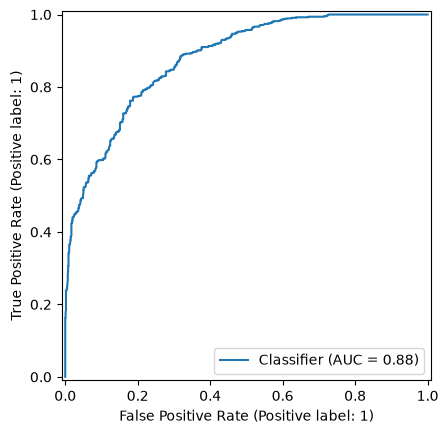

In [48]:
# set up the x/y data for model fitting
X = merged.drop(columns=['class', 'SampleWeight'])
y = merged['class']
sample_weight = merged['SampleWeight']

# fit and evaluate the model under naive conditions
maxent.fit(X, y, sample_weight=sample_weight)
ypred = maxent.predict(X)

print(f"Unweighted naive AUC score: {metrics.roc_auc_score(y, ypred):0.3f}")
RocCurveDisplay.from_predictions(y, ypred)
print(f"Weighted naive AUC score  : {metrics.roc_auc_score(y, ypred, sample_weight=sample_weight):0.3f}")

fullData=[metrics.roc_auc_score(y, ypred),metrics.roc_auc_score(y, ypred, sample_weight=sample_weight)]

**Interpretation:** Why might evaluating the same rows used to fit a model give an overly encouraging impression of performance? Since the model is fitted to those rows, the preformance will already be good, compared to areas that the model hasnt seen.

## 11. Make a geographic train/test split

Use `ela.checkerboard_split(merged, grid_size=50_000)` to divide points into alternating 50 km squares. This distance is in meters because `merged` is projected.

Check the class counts in both groups: each needs presence and background rows to calculate AUC. The provided plotting recipe adds a split label for display only.


Training labels:
class
0    489
1    406
Name: count, dtype: int64
Test labels:
class
0    511
1    248
Name: count, dtype: int64


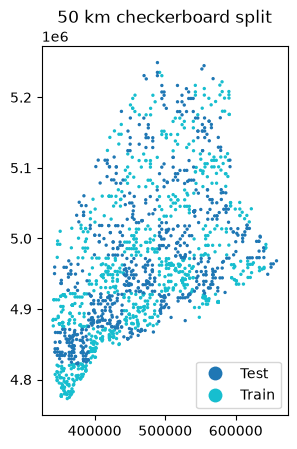

In [30]:
grid_size = 50_000
train, test = ela.checkerboard_split(merged, grid_size=grid_size)
print("Training labels:")
print(train["class"].value_counts())
print("Test labels:")
print(test["class"].value_counts())

train["split"] = "Train"
test["split"] = "Test"
checker = ela.stack_geodataframes(train, test)
checker.plot(column="split", markersize=2, legend=True)
plt.title("50 km checkerboard split")
plt.show()


## 12. Refit using training points and evaluate test points

Build training and test predictor tables using only `labels`, as below. Refit `maxent` on the training rows and their weights, then predict the test rows. Calculate unweighted and weighted test AUCs, storing them as `checker_auc` and `checker_weighted_auc`. Plot the test ROC curve.

In weighted AUC, test weights affect the contribution of each test row. They do not mean the model learned from the test labels.


Unweighted checkerboard AUC score: 0.706
Weighted checkerboard AUC score: 0.710


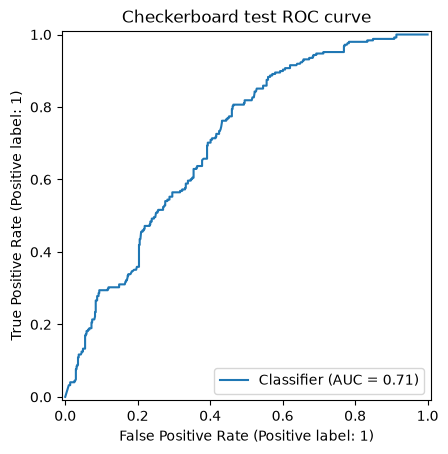

Training labels:
class
0    489
1    406
Name: count, dtype: int64

Test labels:
class
0    511
1    248
Name: count, dtype: int64


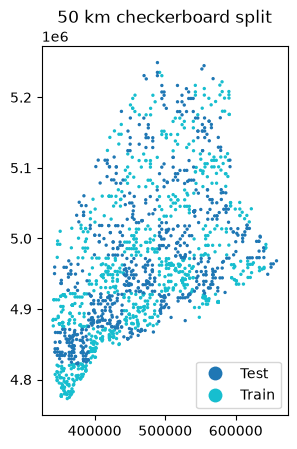

In [53]:
from sklearn import metrics
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

# Create the checkerboard split.
# 50,000 corresponds to 50 km if the CRS uses meters.
grid_size = 50_000
train, test = ela.checkerboard_split(merged, grid_size=grid_size)

# Training data
Xtrain = train[labels]
ytrain = train["class"]
weight_train = train["SampleWeight"]

# Held-out test data
Xtest = test[labels]
ytest = test["class"]
weight_test = test["SampleWeight"]

# Train only on the training checkerboard cells.
maxent.fit(Xtrain, ytrain, sample_weight=weight_train)

# Predict suitability for the held-out test cells.
ypred = maxent.predict(Xtest)

# Calculate and save AUC scores.
checker_auc = metrics.roc_auc_score(ytest, ypred)
checker_weighted_auc = metrics.roc_auc_score(
    ytest, ypred, sample_weight=weight_test
)

print(f"Unweighted checkerboard AUC score: {checker_auc:.3f}")
print(f"Weighted checkerboard AUC score: {checker_weighted_auc:.3f}")

# Plot the test ROC curve.
RocCurveDisplay.from_predictions(ytest, ypred)
plt.title("Checkerboard test ROC curve")
plt.show()

# Check class counts in each split.
print("Training labels:")
print(ytrain.value_counts())

print("\nTest labels:")
print(ytest.value_counts())

# Plot the spatial split.
train = train.copy()
test = test.copy()
train["split"] = "Train"
test["split"] = "Test"

checker = ela.stack_geodataframes(train, test)
checker.plot(column="split", markersize=2, legend=True)
plt.title("50 km checkerboard split")
plt.show()

checkeredData = [checker_auc,checker_weighted_auc]

Unweighted checkerboard AUC score: 0.706
Weighted checkerboard AUC score: 0.710


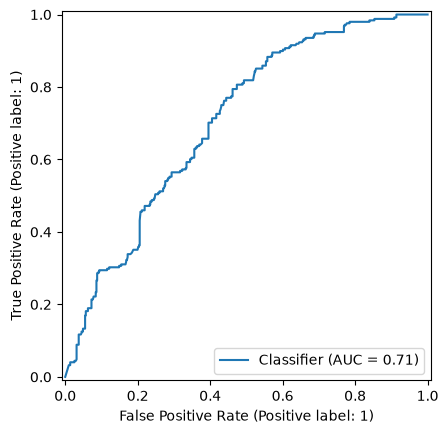

In [42]:
Xtrain = train[labels]
ytrain = train["class"]
weight_train = train["SampleWeight"]

Xtest = test[labels]
ytest = test["class"]
weight_test = test["SampleWeight"]

maxent.fit(Xtrain, ytrain, sample_weight =weight_train)
ypred = maxent.predict(Xtest)

print(f"Unweighted checkerboard AUC score: {metrics.roc_auc_score(ytest, ypred):0.3f}")
print(f"Weighted checkerboard AUC score: {metrics.roc_auc_score(ytest, ypred, sample_weight=weight_test):0.3f}")
# Fit maxent using only Xtrain, ytrain, and weight_train.
# Predict Xtest and calculate checker_auc and checker_weighted_auc.
# Print the scores and plot the test ROC curve.
RocCurveDisplay.from_predictions(ytest, ypred)



## Apply the trained model to the ME clipped rasters

In [35]:
output_raster = "Treefrog-maxent-predictions.tif"
# Use ela.apply_model_to_rasters() to apply the fitted model to the raster stack
# and write the result to the output_raster file

# use rio.open() to read the predicted tif back into memory
# and plot it with imshow()

ela.apply_model_to_rasters(maxent, rasters, output_raster, quiet=True)

# and read into memory
with rio.open(output_raster, 'r') as src:
    pred = src.read(1, masked=True)

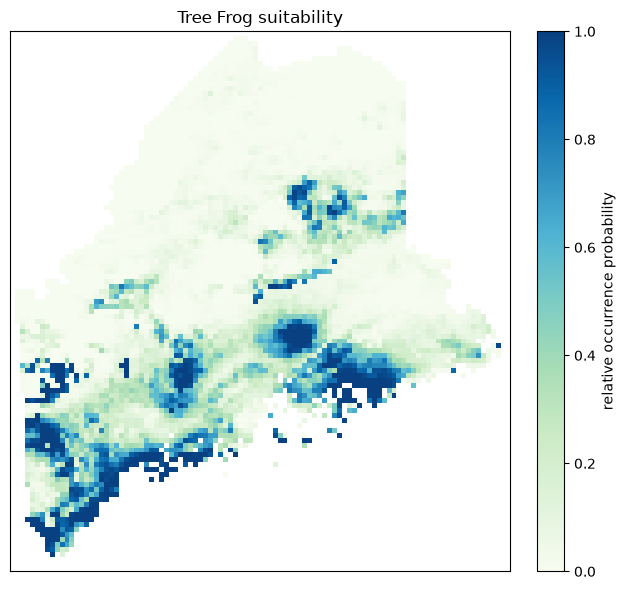

In [37]:
fig, ax = plt.subplots(1, 1, figsize=(7, 6), dpi=100)
plot = ax.imshow(pred, vmin=0, vmax=1, cmap='GnBu')
ax.set_title('Tree Frog suitability')
ax.set_xticks([])
ax.set_yticks([])
cbar = plt.colorbar(plot, ax=ax, label="relative occurrence probability", pad=0.04)
plt.tight_layout()

**Interpretation:** Did test AUC differ from training AUC? Describe what each score evaluates. A lower test score does not automatically prove that spatial autocorrelation caused the difference: the training size and environments also changed. A higher test score does not automatically establish a reliable map. The AUC differed, where the test curve was lower than the training curve, which is to be expected since this is what is being predicted and should have a lower fit. 

## 13. Give the other squares a turn

For a simple two-fold spatial cross-validation, reverse the roles: create a new MaxEnt model, train it using `Xtest`, `ytest`, and `weight_test`, then evaluate its predictions for `Xtrain`. Store the unweighted and weighted scores as `reverse_auc` and `reverse_weighted_auc`.

No new background draw or checkerboard split is needed.


Unweighted reverse AUC score: 0.774
Weighted reverse AUC score: 0.765


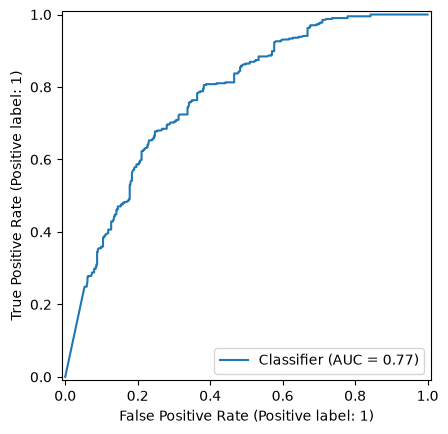

In [50]:
from sklearn.base import clone

Xtrain = train[labels]
ytrain = train["class"]
weight_train = train["SampleWeight"]

Xtest = test[labels]
ytest = test["class"]
weight_test = test["SampleWeight"]

# Create a new model with the same settings.
reverse_model = clone(maxent)

# Fit on the test set and predict the training set.
reverse_model.fit(Xtest, ytest, sample_weight=weight_test)
reverse_ypred = reverse_model.predict(Xtrain)

# Calculate AUC scores against ytrain.
reverse_auc = metrics.roc_auc_score(ytrain, reverse_ypred)
reverse_weighted_auc = metrics.roc_auc_score(
    ytrain, reverse_ypred, sample_weight=weight_train
)

print(f"Unweighted reverse AUC score: {reverse_auc:0.3f}")
print(f"Weighted reverse AUC score: {reverse_weighted_auc:0.3f}")
RocCurveDisplay.from_predictions(ytrain, reverse_ypred)

reverseCheckered = [reverse_auc,reverse_weighted_auc]

**Interpretation:** Were the two directions equally easy to predict? Suggest one geographic or biological reason for a difference. Swapping the regions gives each group a turn as test data; it does not remove every source of observation bias. The reverse was actually better to predit. This could have to do with edge effects. 

## 14. Inspect one buffered leave-one-out split

The lab also demonstrates buffered leave-one-out validation. For each test presence, it removes nearby training points so the model must predict farther from its training data.

Run the code below to inspect **one split**, using a 50 km buffer. No repeated model fitting is required here. `next()` takes just the first split that the splitter produces. This visualization is not a complete validation or an AUC estimate.


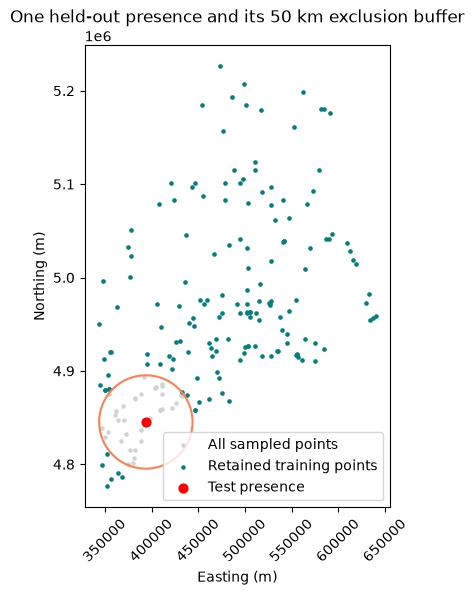

In [46]:
subset = merged.sample(n=min(200, len(merged)), random_state=597).reset_index(drop=True)
distance = 50_000
bloo = ela.BufferedLeaveOneOut(distance=distance)
train_idx, test_idx = next(bloo.split(subset, class_label="class"))
buffer_train = subset.iloc[train_idx]
buffer_test = subset.iloc[test_idx]

fig, ax = plt.subplots(figsize=(6, 6))
subset.plot(ax=ax, color="lightgray", markersize=5, label="All sampled points")
buffer_train.plot(ax=ax, color="teal", markersize=5, label="Retained training points")
buffer_test.buffer(distance).boundary.plot(ax=ax, color="coral")
buffer_test.plot(ax=ax, color="red", markersize=40, label="Test presence")
ax.legend()
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.tick_params(axis="x", labelrotation=45)
ax.set_title("One held-out presence and its 50 km exclusion buffer")
plt.show()


**Interpretation:** What happened to points inside the buffer? How does this test a different prediction question from randomly withholding records? Explain why a single held-out presence cannot by itself give a ROC AUC. The points inside the buffer are not used to train. This may a better way to deal with spatial autocorrelation bias. A single held out point does not give a ROC AUC because it is not testing true or false positives/negatives, rather it is removing the possible influence that certain points have on the model. 

## 15. Summarize and save your results

Make a three-row table with evaluation names, unweighted AUCs, and weighted AUCs:

* Training rows scored by the all-data model.
* First checkerboard direction: train on `train`, evaluate `test`.
* Reversed direction: train on `test`, evaluate `train`.

Save it as `Assignment08_auc_scores.csv`, without a DataFrame index. Save `merged` as `Assignment08_modeling_points.gpkg` using `driver="GPKG"`, preserving its geometry, climate columns, labels, weights, and projected CRS.


In [57]:
# Build an AUC summary table from the six scores you stored.
# Display it and save it to Assignment08_auc_scores.csv.
# Save merged to Assignment08_modeling_points.gpkg.

summary_table = pd.DataFrame(
    [fullData, checkeredData, reverseCheckered],
    index=["Full data", "Checkered", "Reversed checkered"],
    columns=["AUC", "Weighted AUC"]
)

display(summary_table)

# Save the summary without a DataFrame index.
summary_table.to_csv("Assignment08_auc_scores.csv", index=False)

# Save all columns, geometry, and the existing projected CRS.
merged.to_file(
    "Assignment08_modeling_points.gpkg",
    driver="GPKG",
    index=False
)

,AUC,Weighted AUC
Full data,0.878334,0.878030
Checkered,0.706458,0.710452
Reversed checkered,0.773993,0.765444


## Final reflection

Answer each question in two or three sentences, using your results.

1. Which preparation tasks did elapid simplify compared with earlier labs? elapid simplified much of the raster matching steps. It also allowed to sample background data more easily.
2. What do background sampling, geographic sample weights, and spatial train/test splitting each change? Background sampling changes the range of conditions sampled for the model, sample weights account for spatial autocorrelation, and splitting test/training data makes the model robust to random effects and allows for model evaluation. 
3. Why do high AUC and a convincing ROC curve not establish a probability that your species occurs at a location? This only serves to understand model performance and not probability of occurence.
4. What additional data or evaluation would most improve confidence in predictions for your species?
If the treefrog is related to a forest type then that could be essential for the model and may improve the prediction.

## Submit your work

Restart the kernel and run the notebook from top to bottom. Check your figures, AUC table, saved points, and written answers. Commit and push the completed notebook and the two output files to your class GitHub repository.

```bash
git add docs/assignments/Assignment-08-SDM-Software.ipynb docs/assignments/Assignment08_auc_scores.csv docs/assignments/Assignment08_modeling_points.gpkg
git commit -m "Complete elapid SDM assignment"
git push
```

## References

* [elapid geospatial tools](https://earth-chris.github.io/elapid/module/geo/)
* [elapid MaxEnt model](https://earth-chris.github.io/elapid/sdm/maxent/)
* [elapid spatial train/test splitting](https://earth-chris.github.io/elapid/module/train_test_split/)
